In [1]:
import sys, pandas, sklearn
print(sys.executable)
print("OK")

d:\SERTIFIKASI DAN PELATIHAN\Bootcamp AI Engineer\TUGAS PROJEK BOOTCAMP FRAUD TRANSACTION\.venv\Scripts\python.exe
OK


In [3]:
import urllib.request
print(urllib.request.urlopen("https://www.openml.org", timeout=15).status)

200


In [5]:
from pathlib import Path

cache = Path(r"C:\Users\Lenovo\scikit_learn_data\openml\openml.org\data\v1\download\1673544\creditcard.arff.gz")
cache.unlink(missing_ok=True)
print("Cache dibersihkan")

Cache dibersihkan


In [6]:
import pandas as pd

url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(url)

df.to_csv("data/creditcard.csv", index=False)
print(df.shape)
print(df["Class"].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/creditcard.csv")
print(df.shape)
print("Nilai kosong:", df.isna().sum().sum())
print("Duplikat:", df.duplicated().sum())
df[["Time", "Amount", "Class"]].describe()

(284807, 31)
Nilai kosong: 0
Duplikat: 1081


,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


In [8]:
print(df["Class"].value_counts(normalize=True).round(5))

Class
0    0.99827
1    0.00173
Name: proportion, dtype: float64


In [9]:
print(df.groupby("Class")["Amount"].describe().round(2))

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


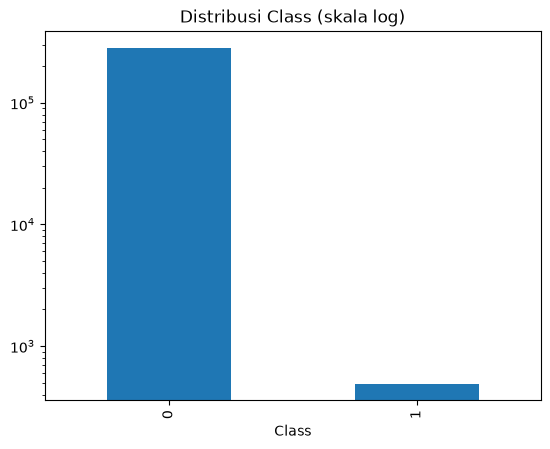

In [10]:
df["Class"].value_counts().plot(
    kind="bar",
    logy=True,
    title="Distribusi Class (skala log)"
)
plt.show()

In [11]:
corr = df.corr()["Class"].drop("Class").sort_values()
print(corr.head(5))
print(corr.tail(5))

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876
Name: Class, dtype: float64


In [12]:
df_model = df.drop_duplicates().copy()

print("Sebelum:", df.shape)
print("Sesudah:", df_model.shape)
print(df_model["Class"].value_counts())

Sebelum: (284807, 31)
Sesudah: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [13]:
sebelum = df.shape[0]
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Baris:", sebelum, "->", df_clean.shape[0])
print(df_clean["Class"].value_counts())

Baris: 284807 -> 283726
Class
0    283253
1       473
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="Class")
y = df_clean["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print("Penipuan di latih:", y_train.sum(), "| di uji:", y_test.sum())

(226980, 30) (56746, 30)
Penipuan di latih: 378 | di uji: 95


In [15]:
#langkah 8

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler

preprocess = ColumnTransformer(
    [("scale", RobustScaler(), ["Time", "Amount"])],
    remainder="passthrough",
)

In [17]:
#langkah 9

import warnings
warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = ["average_precision", "recall", "precision", "f1"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "pr_auc": res["test_average_precision"].mean(),
        "recall": res["test_recall"].mean(),
        "precision": res["test_precision"].mean(),
        "f1": res["test_f1"].mean(),
    })
    print("selesai:", name)

hasil = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
hasil.round(4)

selesai: Dummy
selesai: Logistic Regression
selesai: Random Forest
selesai: Hist Gradient Boosting


,model,pr_auc,recall,precision,f1
2,Random Forest,0.8249,0.7354,0.9395,0.8232
1,Logistic Regression,0.7545,0.9206,0.0597,0.1120
3,Hist Gradient Boosting,0.7204,0.8386,0.4591,0.5922
0,Dummy,0.0017,0.0000,0.0000,0.0000


In [18]:
from sklearn.model_selection import RandomizedSearchCV

pipe_rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42)),
])

param_dist = {
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.3, 0.5],
    "model__max_depth": [None, 20, 30],
}

search = RandomizedSearchCV(
    pipe_rf, param_dist, n_iter=4, scoring="average_precision",
    cv=cv, random_state=42, verbose=2,
)
search.fit(X_train, y_train)

print(search.best_params_)
print("CV PR-AUC terbaik:", round(search.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5; total time=  17.7s
[CV] END model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5; total time=  17.7s
[CV] END model__max_depth=None, model__max_features=0.5, model__min_samples_leaf=5; total time=  18.0s
[CV] END model__max_depth=20, model__max_features=0.3, model__min_samples_leaf=2; total time=  10.7s
[CV] END model__max_depth=20, model__max_features=0.3, model__min_samples_leaf=2; total time=  11.8s
[CV] END model__max_depth=20, model__max_features=0.3, model__min_samples_leaf=2; total time=  11.6s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=1; total time=   7.1s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=1; total time=   6.9s
[CV] END model__max_depth=20, model__max_features=sqrt, model__min_samples_leaf=1; total time=   7.5s
[CV] END model__max_de

In [19]:
#langkah 11

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

best = search.best_estimator_
proba_cv = cross_val_predict(best, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, proba_cv)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
i = f1.argmax()
threshold = float(thr[i])

print("Ambang terbaik:", round(threshold, 3))
print("Precision:", round(prec[i], 3), "Recall:", round(rec[i], 3), "F1:", round(f1[i], 3))

Ambang terbaik: 0.34
Precision: 0.905 Recall: 0.804 F1: 0.852


Ambang      : 0.34
PR-AUC      : 0.8158
Precision   : 0.9459
Recall      : 0.7368
F1 (penipuan): 0.8284
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56651
    Penipuan       0.95      0.74      0.83        95

    accuracy                           1.00     56746
   macro avg       0.97      0.87      0.91     56746
weighted avg       1.00      1.00      1.00     56746



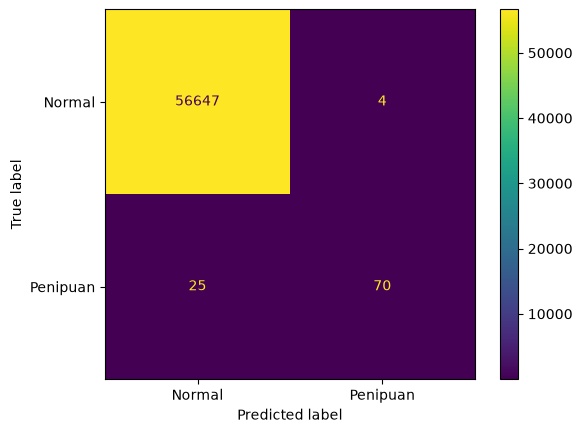

In [20]:
#Langkah 12: Evaluasi di data uji (jalankan sekali saja)

from sklearn.metrics import (average_precision_score, classification_report,
                             ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score)

proba_test = best.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= threshold).astype(int)

print("Ambang      :", round(threshold, 3))
print("PR-AUC      :", round(average_precision_score(y_test, proba_test), 4))
print("Precision   :", round(precision_score(y_test, pred_test), 4))
print("Recall      :", round(recall_score(y_test, pred_test), 4))
print("F1 (penipuan):", round(f1_score(y_test, pred_test), 4))
print(classification_report(y_test, pred_test, target_names=["Normal", "Penipuan"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["Normal", "Penipuan"])
plt.show()

In [21]:
#Langkah 13: Pemeriksaan overfitting dan fitur penting

proba_train = best.predict_proba(X_train)[:, 1]
print("PR-AUC latih:", round(average_precision_score(y_train, proba_train), 4))
print("PR-AUC uji  :", round(average_precision_score(y_test, proba_test), 4))

nama = ["Time", "Amount"] + [c for c in X.columns if c not in ("Time", "Amount")]
imp = pd.Series(best.named_steps["model"].feature_importances_, index=nama)
imp.sort_values(ascending=False).head(10).round(4)

PR-AUC latih: 0.9947
PR-AUC uji  : 0.8158


V14    0.3057
V12    0.1525
V10    0.1357
V4     0.0843
V17    0.0727
V11    0.0467
V3     0.0302
V16    0.0213
V8     0.0145
V7     0.0132
dtype: float64

In [23]:
#Langkah 14: Simpan model, ambang, dan data contoh

import joblib, json, os

os.makedirs("artifacts", exist_ok=True)
joblib.dump(best, "artifacts/fraud_model.joblib")

metrics = {
    "threshold": float(threshold),
    "test_pr_auc": float(average_precision_score(y_test, proba_test)),
    "test_precision": float(precision_score(y_test, pred_test)),
    "test_recall": float(recall_score(y_test, pred_test)),
    "test_f1": float(f1_score(y_test, pred_test)),
    "cv_pr_auc": float(search.best_score_),
    "best_params": search.best_params_,
}
with open("artifacts/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

hasil.to_csv("artifacts/model_comparison.csv", index=False)

# data contoh untuk demo aplikasi: 5 penipuan yang terdeteksi + 15 transaksi normal
demo = pd.concat([
    X_test[(y_test == 1) & (pred_test == 1)].head(5),
    X_test[y_test == 0].sample(15, random_state=42),
]).sample(frac=1, random_state=42)
demo.to_csv("data/contoh_transaksi.csv", index=False)
demo.assign(Class=y_test.loc[demo.index]).to_csv(
    "data/contoh_transaksi_berlabel.csv", index=False)

print(os.listdir("artifacts"))

['fraud_model.joblib', 'metrics.json', 'model_comparison.csv']


In [24]:
#Langkah 15: Catat di MLflow

import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("fraud-detection")

with mlflow.start_run(run_name="random_forest_tuned"):
    mlflow.log_params(search.best_params_)
    mlflow.log_param("threshold", float(threshold))
    for k in ["cv_pr_auc", "test_pr_auc", "test_precision", "test_recall", "test_f1"]:
        mlflow.log_metric(k, metrics[k])
    mlflow.log_artifact("artifacts/fraud_model.joblib")
    mlflow.log_artifact("artifacts/metrics.json")
    mlflow.log_artifact("artifacts/model_comparison.csv")

print("Selesai dicatat")

2026/11/21 14:28:01 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 14:28:01 INFO mlflow.store.db.utils: Updating database tables
2026/11/21 14:28:04 INFO mlflow.tracking.fluent: Experiment with name 'fraud-detection' does not exist. Creating a new experiment.


Selesai dicatat


ambang                    0.34000
jumlah_data_uji       56746.00000
accuracy                  0.99949
precision_penipuan        0.94590
recall_penipuan           0.73680
f1_penipuan               0.82840
pr_auc                    0.81580
true_negative         56647.00000
false_positive            4.00000
false_negative           25.00000
true_positive            70.00000


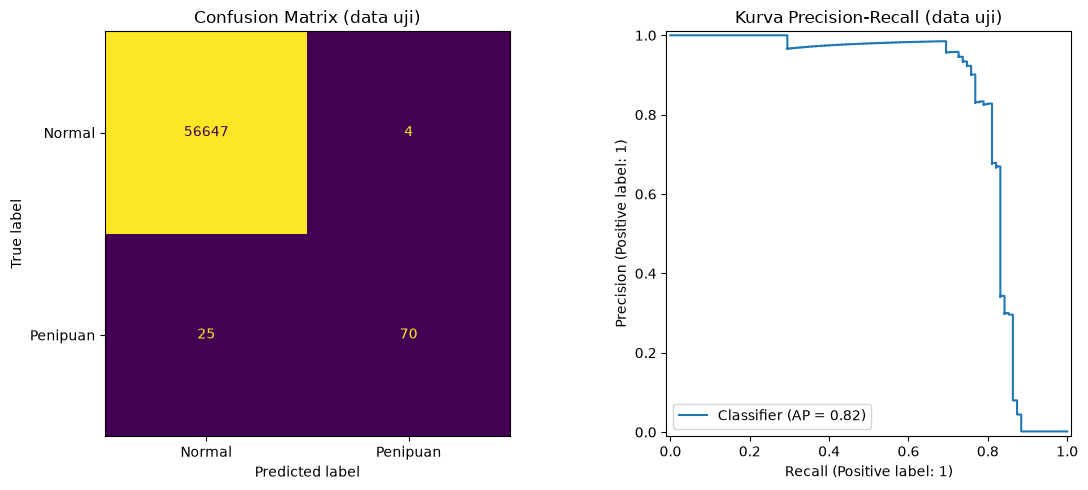


Penipuan yang lolos: 25
Median Amount lolos     : 3.76
Median Amount tertangkap: 31.99


,Time,Amount,probabilitas_penipuan
6932,9064.0,1809.68,0.2998
93461,64585.0,0.00,0.2887
228883,146026.0,2.22,0.2376
4886,4462.0,239.93,0.1698
14285,25426.0,3.76,0.1695
87035,61646.0,19.04,0.1499
239334,150494.0,1.00,0.1497
10442,17187.0,3.79,0.0899
68058,52934.0,0.76,0.0799
145246,87202.0,451.27,0.0399


In [25]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, PrecisionRecallDisplay,
)

# Muat ulang data dan bagi dengan pengaturan yang sama seperti sebelumnya
df_clean = pd.read_csv("data/creditcard.csv").drop_duplicates().reset_index(drop=True)
X = df_clean.drop(columns="Class")
y = df_clean["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Muat model dan ambang yang tersimpan
model = joblib.load("artifacts/fraud_model.joblib")
with open("artifacts/metrics.json") as f:
    threshold = json.load(f)["threshold"]

proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

laporan = {
    "ambang": round(float(threshold), 3),
    "jumlah_data_uji": int(len(y_test)),
    "accuracy": round(accuracy_score(y_test, pred), 5),
    "precision_penipuan": round(precision_score(y_test, pred), 4),
    "recall_penipuan": round(recall_score(y_test, pred), 4),
    "f1_penipuan": round(f1_score(y_test, pred), 4),
    "pr_auc": round(average_precision_score(y_test, proba), 4),
    "true_negative": int(tn),
    "false_positive": int(fp),
    "false_negative": int(fn),
    "true_positive": int(tp),
}
with open("artifacts/evaluation_report.json", "w") as f:
    json.dump(laporan, f, indent=2)
print(pd.Series(laporan).to_string())

# Grafik: confusion matrix dan kurva precision-recall
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Normal", "Penipuan"],
    ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix (data uji)")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[1])
axes[1].set_title("Kurva Precision-Recall (data uji)")
plt.tight_layout()
fig.savefig("artifacts/evaluasi_fraud.png", dpi=150)
plt.show()

# Analisis penipuan yang lolos (false negative)
hasil_uji = X_test.copy()
hasil_uji["Class"] = y_test
hasil_uji["probabilitas_penipuan"] = proba
lolos = hasil_uji[(hasil_uji["Class"] == 1) & (proba < threshold)] \
    .sort_values("probabilitas_penipuan", ascending=False)
lolos[["Time", "Amount", "probabilitas_penipuan"]].to_csv(
    "artifacts/penipuan_lolos.csv", index=False)
print("\nPenipuan yang lolos:", len(lolos))
print("Median Amount lolos     :", round(lolos["Amount"].median(), 2))
print("Median Amount tertangkap:", round(
    hasil_uji[(hasil_uji["Class"] == 1) & (proba >= threshold)]["Amount"].median(), 2))
lolos[["Time", "Amount", "probabilitas_penipuan"]].head(10).round(4)